# EDA · Intel Image Classification
Chạy từ kernel Python của D:/Lab2. Tái tạo bản chia seed 42 trong bộ nhớ. Thống kê chất lượng, màu và ví dụ chỉ lấy từ train. Kiểm tra test giới hạn ở kiểm kê và đối chiếu trùng. Các bảng chi tiết được lưu trong `outputs/eda-seed42`.

Counter({'train': 11208, 'test': 3000, 'validation': 2798})


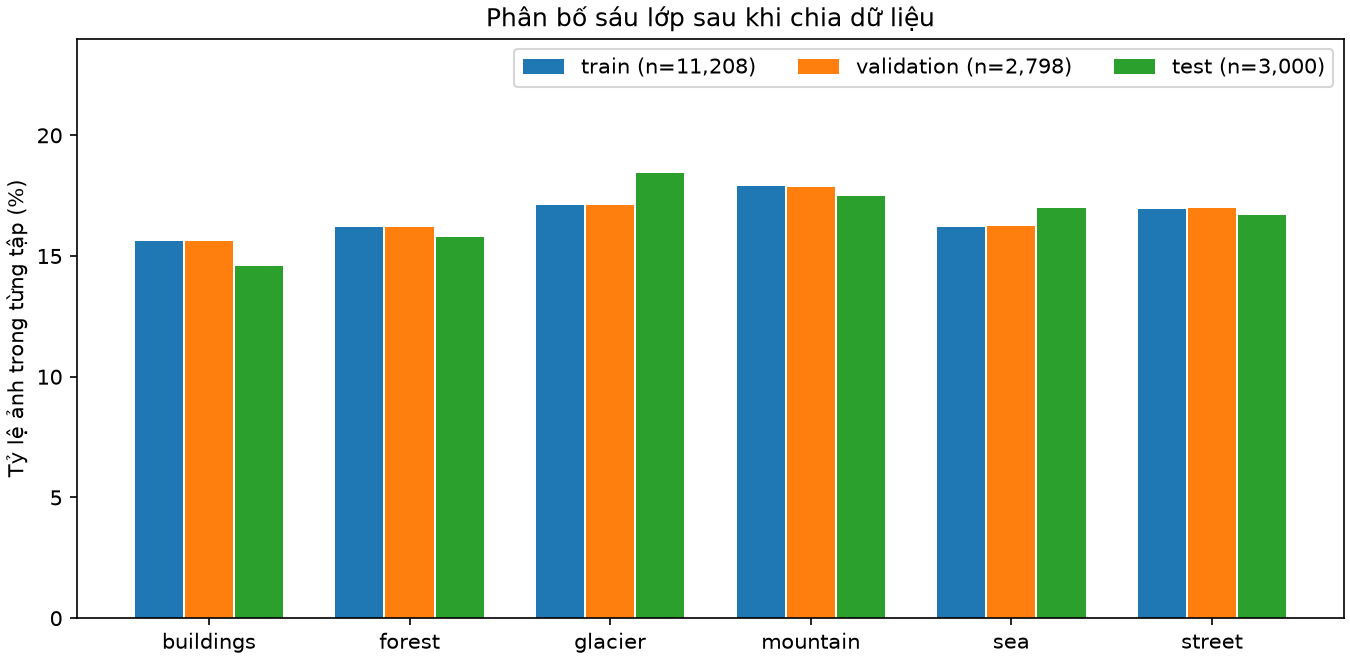

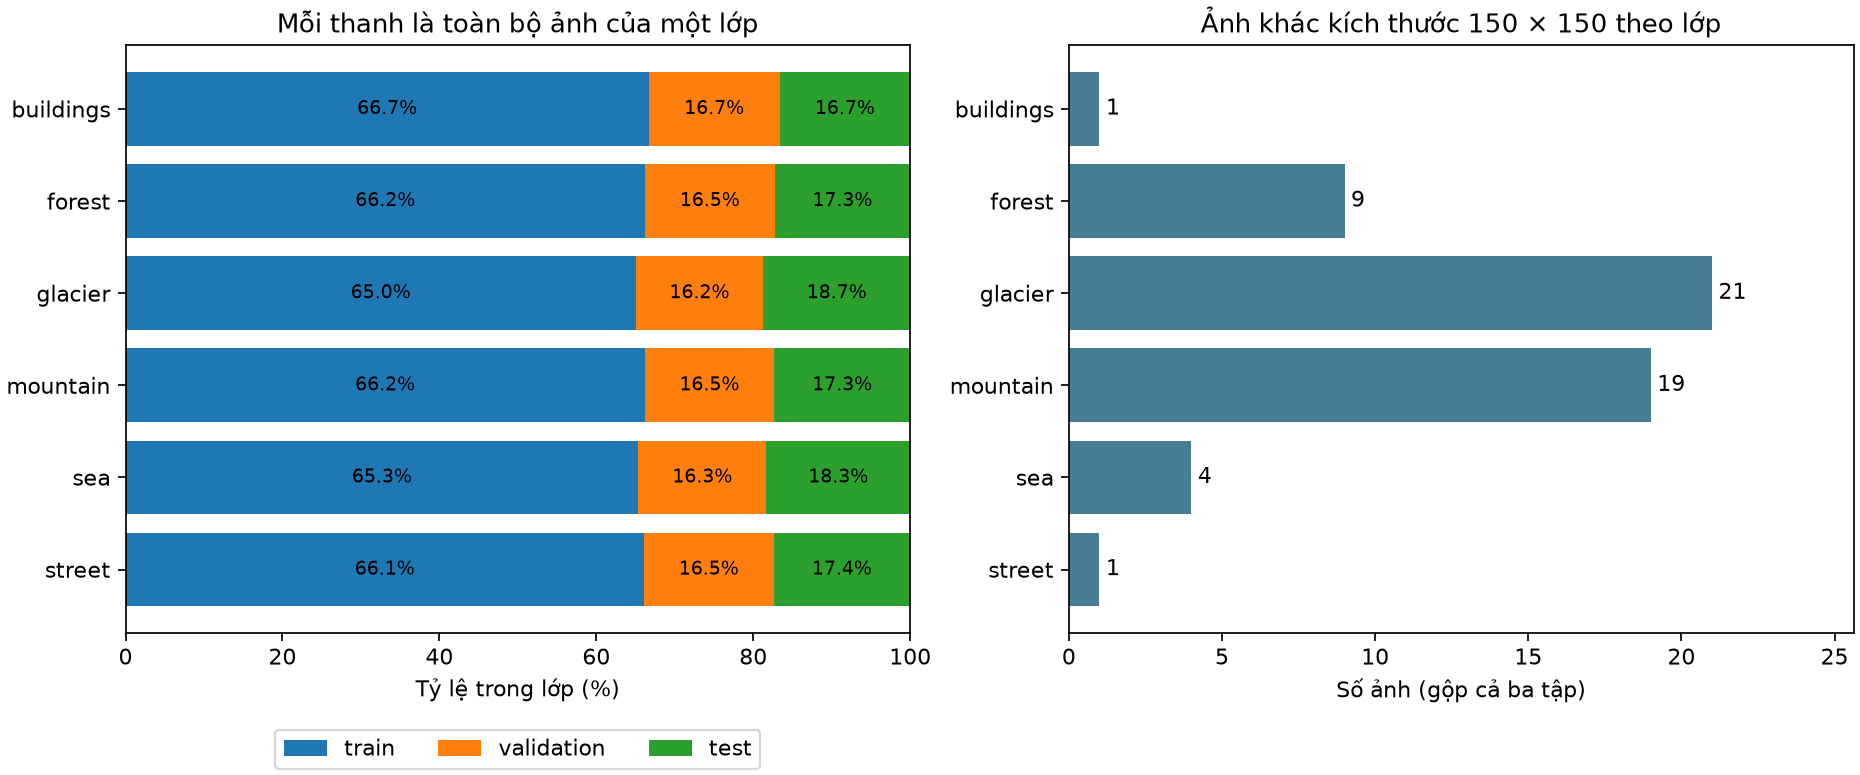

In [1]:
from pathlib import Path
import os, sys, csv, random
from collections import Counter, defaultdict
import numpy as np
from PIL import Image, ImageFilter
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as Show
root=Path('D:/Lab2')
sys.path.insert(0,str(root))
from src.phases.phase_02_data import inspect_images, locate, RAW, CLASSES, make_split
out=root/'outputs/eda-seed42'
out.mkdir(exist_ok=True,parents=True)
def save(name, rows, fields):
    with (out/name).open('w',encoding='utf-8-sig',newline='') as f:
        w=csv.DictWriter(f,fieldnames=fields,extrasaction='ignore'); w.writeheader(); w.writerows(rows)
def plot(name):
    plt.tight_layout(); plt.savefig(out/name,dpi=125); plt.close()
    display(Show(filename=str(out/name)))
dev=inspect_images(locate('seg_train'),'train')
test=inspect_images(locate('seg_test'),'test')
rows,removed=make_split(dev,test,42,True)
train=[r for r in rows if r['split']=='train']
assert len(train)==11208 and len(rows)==17006
print(Counter(r['split'] for r in rows))
save('exact-exclusions.csv',removed,['relative_path','class_name','sha256','reason'])
for name in ['phan-bo.png','theo-lop.png']:
    display(Show(filename=str(out/name)))

## Kiểm kê và phân bố kích thước
Đếm định dạng theo bộ giải mã, thử đọc cả tập demo. Histogram dùng trục log cho số lượng để thấy nhóm ngoại lệ nhỏ.

Counter({('seg_train', 'JPEG'): 14034, ('seg_pred', 'JPEG'): 7301, ('seg_test', 'JPEG'): 3000}) Counter({('seg_train', 'RGB'): 14034, ('seg_pred', 'RGB'): 7301, ('seg_test', 'RGB'): 3000}) decode errors: 0


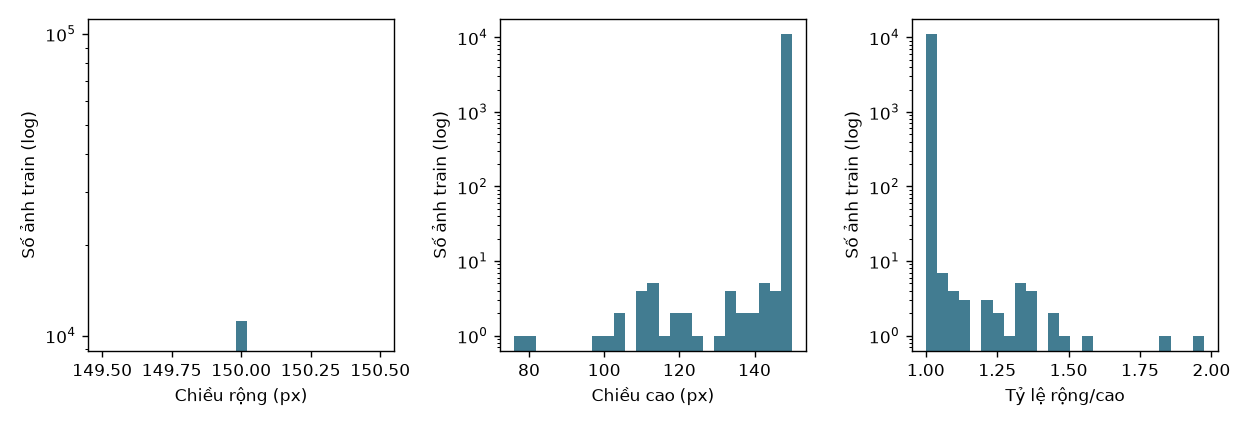

In [2]:
fmt=Counter(); modes=Counter(); errors=[]
for path in RAW.rglob('*'):
    if not path.is_file(): continue
    part=path.relative_to(RAW).parts[0]
    try:
        with Image.open(path) as im:
            im.load(); fmt[part,im.format]+=1; modes[part,im.mode]+=1
    except OSError as exc:
        errors.append(dict(path=str(path.relative_to(RAW)),error=str(exc)))
save('decode-errors.csv',errors,['path','error'])
print(fmt, modes, 'decode errors:',len(errors))
fig,axes=plt.subplots(1,3,figsize=(10,3.4))
for ax,values,label in zip(axes,[[r['width'] for r in train],[r['height'] for r in train],[r['width']/r['height'] for r in train]],['Chiều rộng (px)','Chiều cao (px)','Tỷ lệ rộng/cao']):
    ax.hist(values,bins=25,log=True,color='#427c91'); ax.set_xlabel(label); ax.set_ylabel('Số ảnh train (log)')
plot('kich-thuoc-train.png')

## Chất lượng và màu trước augmentation
Độ sáng là trung bình ảnh xám PIL (0–255), tương phản là độ lệch chuẩn. Phương sai Laplacian bốn hướng đo độ sắc của biên. Sai lệch tuyệt đối trung bình so với lọc median 3×3 là chỉ báo dao động cục bộ, cũng nhạy với vân bề mặt. Không dùng các chỉ báo này để tự động loại ảnh.

RGB mean/std [0,1] [0.42971754 0.45681098 0.45279658] [0.26911153 0.26789089 0.29833773]
brightness [ 40.43527134 116.35777664 182.18571884]
contrast [26.97744934 59.13325882 91.51534653]
edge_var [  357.73002533  6484.73730469 26124.58007813]
median_residual [ 1.64767731 10.05375576 25.43914946]


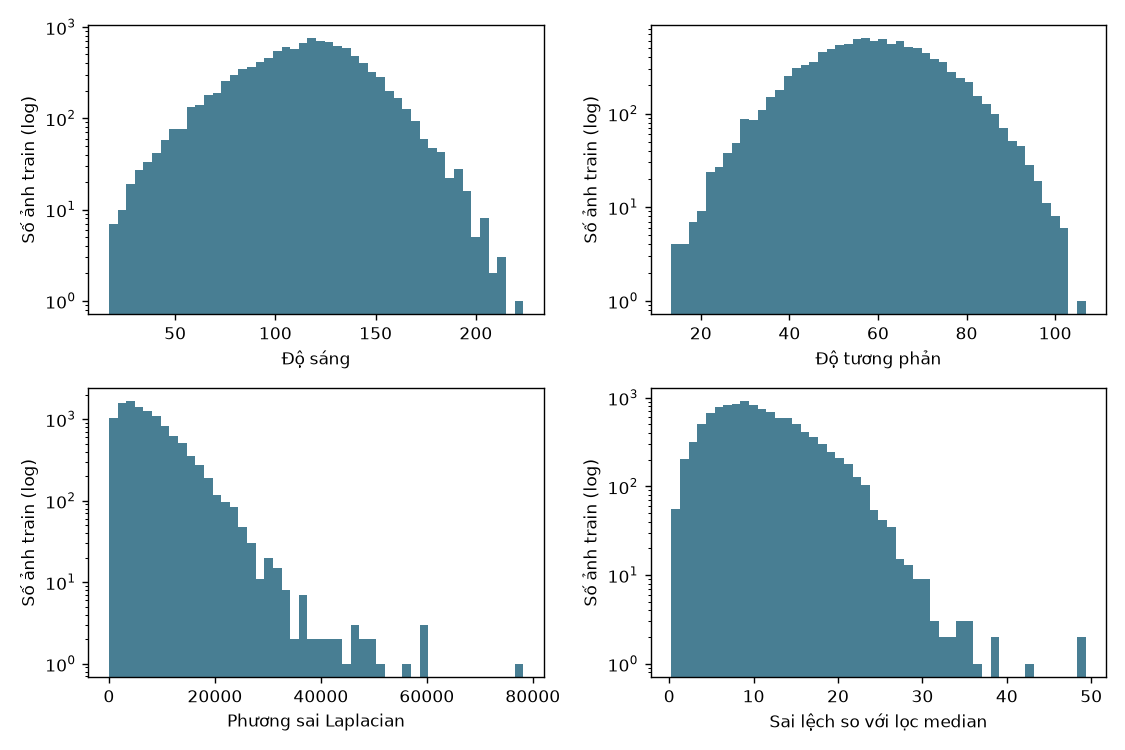

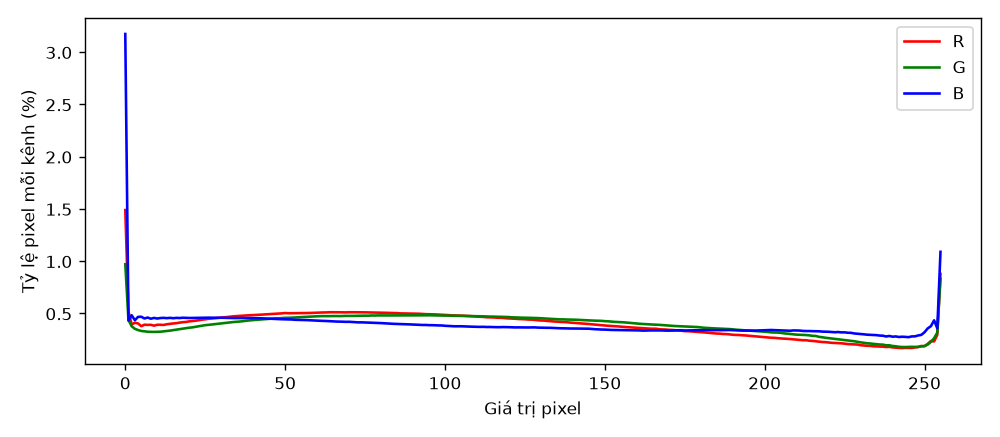

In [3]:
hist=np.zeros((3,256),dtype=np.int64); q=[]
keys=['brightness','contrast','edge_var','median_residual']
hashes=[]
for r in rows:
    with Image.open(RAW/r['relative_path']) as im:
        gray=im.convert('L')
        small=np.asarray(gray.resize((9,8),Image.Resampling.LANCZOS))
        hashes.append(int.from_bytes(np.packbits(small[:,1:]>small[:,:-1]).tobytes(),'big'))
        if r['split']!='train': continue
        a=np.asarray(im.convert('RGB'))
        for k in range(3): hist[k]+=np.bincount(a[:,:,k].ravel(),minlength=256)
        y=np.asarray(gray,dtype=np.float32)
        lap=y[1:-1,:-2]+y[1:-1,2:]+y[:-2,1:-1]+y[2:,1:-1]-4*y[1:-1,1:-1]
        q.append(dict(**r,brightness=float(y.mean()),contrast=float(y.std()),edge_var=float(lap.var()),
                      median_residual=float(np.abs(y-np.asarray(gray.filter(ImageFilter.MedianFilter(3)))).mean())))
save('train-quality.csv',q,['relative_path','class_name']+keys)
v=np.arange(256); means=(hist@v)/hist.sum(axis=1); std=np.sqrt((hist@(v**2))/hist.sum(axis=1)-means**2)
assert np.all(hist.sum(axis=1)==sum(r['width']*r['height'] for r in train))
print('RGB mean/std [0,1]',means/255,std/255)
for key in keys: print(key,np.percentile([r[key] for r in q],[1,50,99]))
fig,axes=plt.subplots(2,2,figsize=(9,6))
for ax,key,label in zip(axes.flat,keys,['Độ sáng','Độ tương phản','Phương sai Laplacian','Sai lệch so với lọc median']):
    ax.hist([r[key] for r in q],bins=48,color='#487e93',log=True); ax.set(xlabel=label,ylabel='Số ảnh train (log)')
plot('chat-luong-train.png')
plt.figure(figsize=(8,3.5))
for k,color in enumerate(['red','green','blue']): plt.plot(v,100*hist[k]/hist[k].sum(),label='RGB'[k],color=color)
plt.xlabel('Giá trị pixel'); plt.ylabel('Tỷ lệ pixel mỗi kênh (%)'); plt.legend()
plot('mau-rgb-train.png')

## Quan sát trong lớp và giữa các lớp
Mỗi hàng gồm 8 ảnh train lấy mẫu không hoàn lại, seed 42. Lưới thứ hai hiển thị cực trị để phân biệt lỗi kỹ thuật với đặc điểm thật của cảnh.

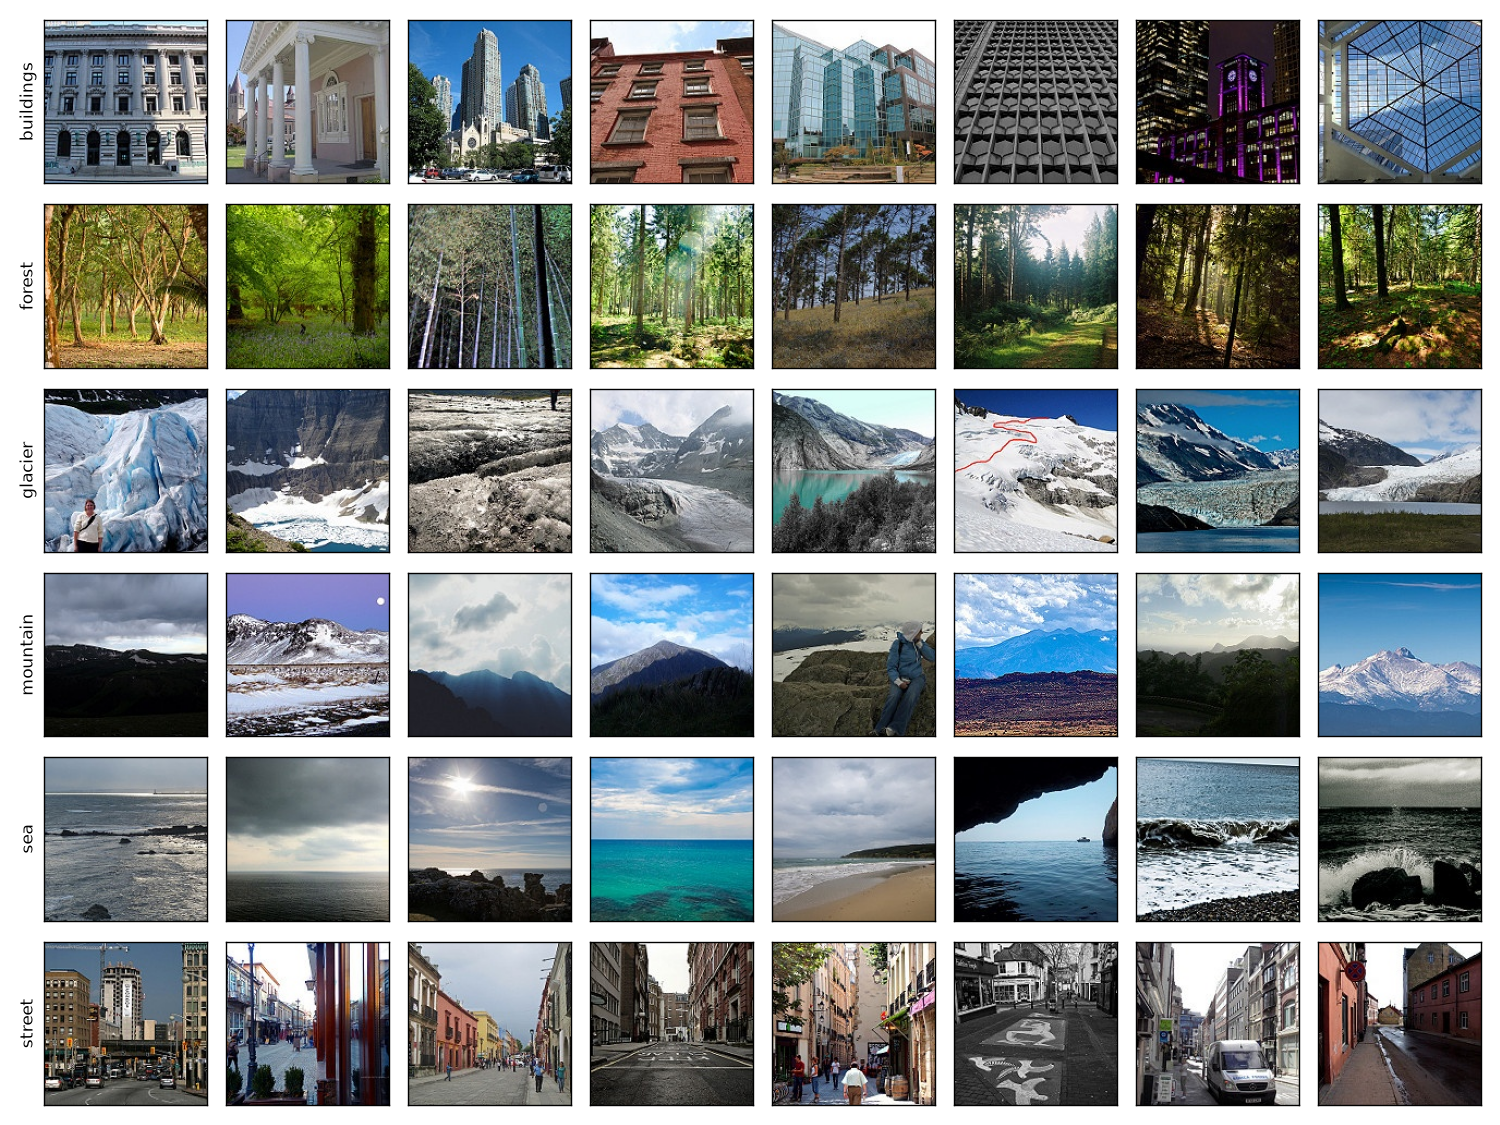

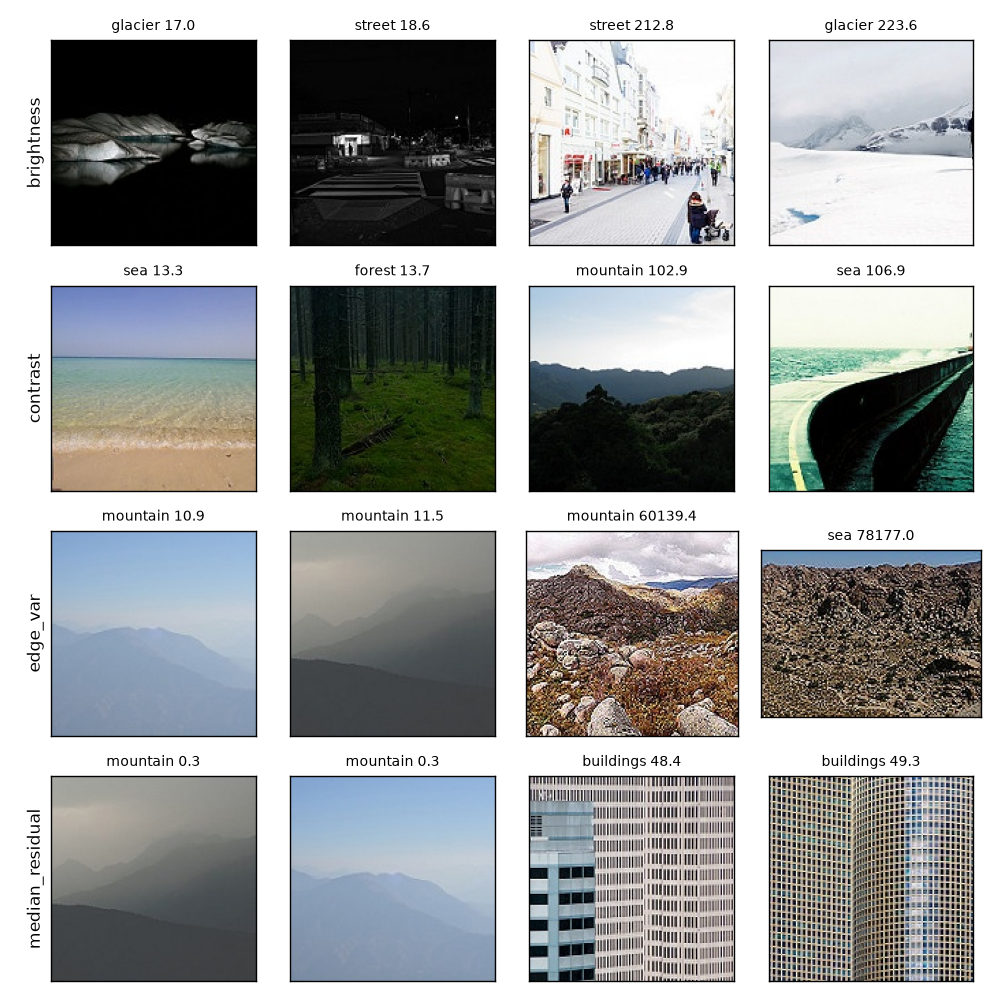

In [4]:
def thumb(ax,r):
    with Image.open(RAW/r['relative_path']) as im: ax.imshow(im.convert('RGB'))
    ax.set_xticks([]); ax.set_yticks([])
rng=random.Random(42)
fig,axes=plt.subplots(6,8,figsize=(12,9))
for c,line in zip(CLASSES,axes):
    for ax,r in zip(line,rng.sample([r for r in train if r['class_name']==c],8)): thumb(ax,r)
    line[0].set_ylabel(c)
plot('48-mau-train.png')
fig,axes=plt.subplots(4,4,figsize=(8,8))
for line,key in zip(axes,keys):
    ordered=sorted(q,key=lambda r:r[key])
    for ax,r in zip(line,ordered[:2]+ordered[-2:]):
        thumb(ax,r); ax.set_title(f"{r['class_name']} {r[key]:.1f}",fontsize=8)
    line[0].set_ylabel(key)
plot('ngoai-le-train.png')

## Audit gần trùng và rò rỉ giữa các tập
So sánh dHash 64 bit với ngưỡng Hamming ≤3. Bốn khối 16 bit giúp tìm đủ mọi cặp trong ngưỡng vì ít nhất một khối phải giống hệt. Mỗi dòng CSV là ứng viên cần kiểm tra thị giác. Dùng nhãn test chỉ để audit.

pairs by split Counter({('train', 'train'): 191, ('test', 'train'): 96, ('train', 'validation'): 48, ('test', 'validation'): 14, ('test', 'test'): 7})
different labels 40


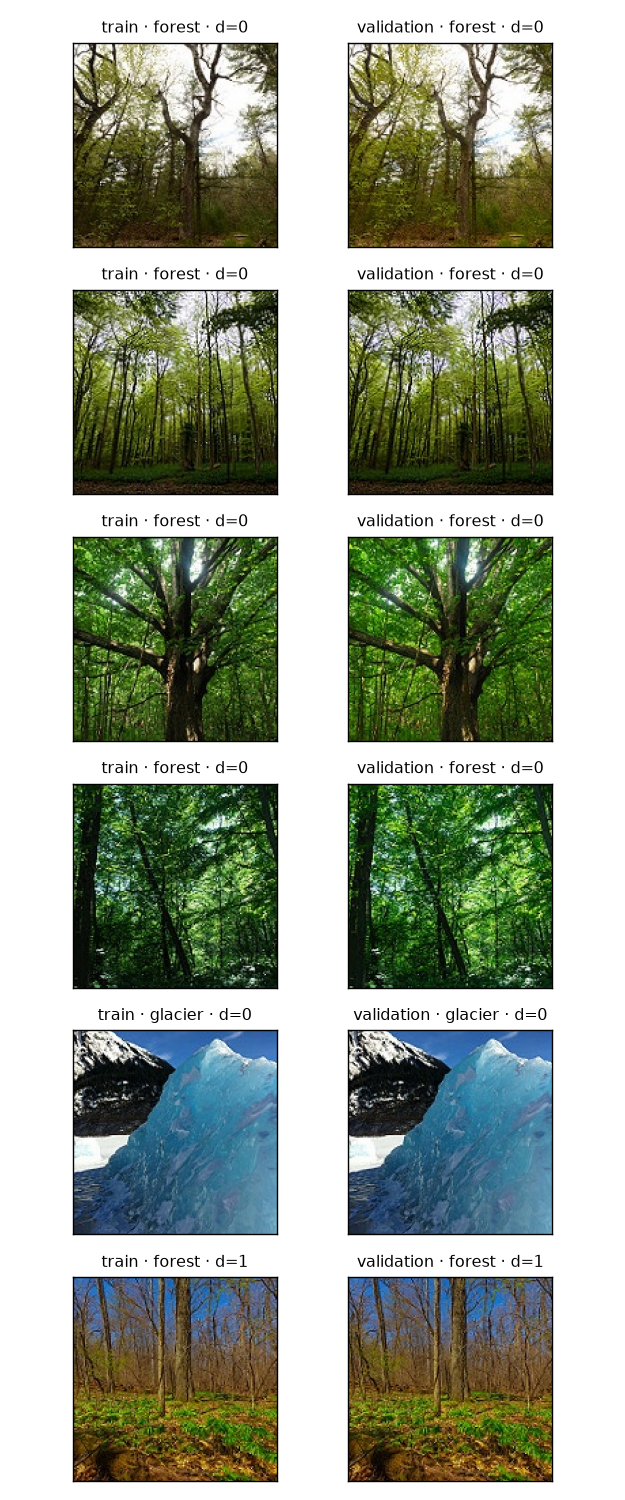

In [5]:
buckets=defaultdict(list); pairs=[]
for i,h in enumerate(hashes):
    chunks=[(j,(h>>(16*j))&65535) for j in range(4)]
    cand={k for ck in chunks for k in buckets[ck]}
    for k in sorted(cand):
        dist=(h^hashes[k]).bit_count()
        if dist>3: continue
        a,b=rows[k],rows[i]
        pairs.append(dict(a=a['relative_path'],b=b['relative_path'],split_a=a['split'],split_b=b['split'],
                          label_a=a['class_name'],label_b=b['class_name'],distance=dist))
    for ck in chunks: buckets[ck].append(i)
save('near-pairs.csv',pairs,['a','b','split_a','split_b','label_a','label_b','distance'])
print('pairs by split',Counter(tuple(sorted((p['split_a'],p['split_b']))) for p in pairs))
print('different labels',sum(p['label_a']!=p['label_b'] for p in pairs))
other=sorted((p for p in pairs if 'test' not in [p['split_a'],p['split_b']]),key=lambda p:(p['split_a']==p['split_b'],p['distance'],p['a']))
if other:
    sample=other[:min(6,len(other))]
    fig,axes=plt.subplots(len(sample),2,figsize=(5,2*len(sample)),squeeze=False)
    for line,p in zip(axes,sample):
        for ax,side in zip(line,['a','b']):
            thumb(ax,{'relative_path':p[side]}); ax.set_title(f"{p['split_'+side]} · {p['label_'+side]} · d={p['distance']}",fontsize=9)
    plot('cap-can-kiem-tra.png')

## Kết luận trước huấn luyện

Sáu lớp gần cân bằng. Có 40 ảnh train không vuông, cần kiểm crop trên ảnh ngang. Giữ chuẩn hóa ImageNet và theo dõi recall từng lớp. Một số cảnh núi trong sương có độ sắc thấp và mặt tiền nhiều cửa sổ có độ dao động cục bộ cao. Không loại ảnh theo riêng các chỉ số này.

Có 48 cặp ứng viên train–validation; sáu cặp hiển thị có cảnh gần như lặp lại. Cần xác minh nhóm ảnh, xử lý nhóm chạm test, chia theo nhóm và đối chiếu lại số lượng trước khi train. [Báo cáo đầy đủ](../outputs/eda-seed42/EDA.md).